#### importing libriaries


In [ ]:
import numpy as np
import pandas as pd
from skimpy import skim
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from sklearn.metrics import accuracy_score, classification_report
import mlflow
import mlflow.sklearn
from fastapi import FastAPI 
import joblib



#### Reading Data

In [49]:
data=pd.read_csv('loan_approval_dataset.csv')

In [50]:
data

,loan_id,no_of_dependents,education,self_employed,income_annum,loan_amount,loan_term,cibil_score,residential_assets_value,commercial_assets_value,luxury_assets_value,bank_asset_value,loan_status
0,1,2,Graduate,No,9600000,29900000,12,778,2400000,17600000,22700000,8000000,Approved
1,2,0,Not Graduate,Yes,4100000,12200000,8,417,2700000,2200000,8800000,3300000,Rejected
2,3,3,Graduate,No,9100000,29700000,20,506,7100000,4500000,33300000,12800000,Rejected
3,4,3,Graduate,No,8200000,30700000,8,467,18200000,3300000,23300000,7900000,Rejected
4,5,5,Not Graduate,Yes,9800000,24200000,20,382,12400000,8200000,29400000,5000000,Rejected
...,...,...,...,...,...,...,...,...,...,...,...,...,...
4264,4265,5,Graduate,Yes,1000000,2300000,12,317,2800000,500000,3300000,800000,Rejected
4265,4266,0,Not Graduate,Yes,3300000,11300000,20,559,4200000,2900000,11000000,1900000,Approved
4266,4267,2,Not Graduate,No,6500000,23900000,18,457,1200000,12400000,18100000,7300000,Rejected
4267,4268,1,Not Graduate,No,4100000,12800000,8,780,8200000,700000,14100000,5800000,Approved


### Data Exploration

In [51]:
data.head()

,loan_id,no_of_dependents,education,self_employed,income_annum,loan_amount,loan_term,cibil_score,residential_assets_value,commercial_assets_value,luxury_assets_value,bank_asset_value,loan_status
0,1,2,Graduate,No,9600000,29900000,12,778,2400000,17600000,22700000,8000000,Approved
1,2,0,Not Graduate,Yes,4100000,12200000,8,417,2700000,2200000,8800000,3300000,Rejected
2,3,3,Graduate,No,9100000,29700000,20,506,7100000,4500000,33300000,12800000,Rejected
3,4,3,Graduate,No,8200000,30700000,8,467,18200000,3300000,23300000,7900000,Rejected
4,5,5,Not Graduate,Yes,9800000,24200000,20,382,12400000,8200000,29400000,5000000,Rejected


In [52]:
skim(data)

╭──────────────────────────────────────────────── skimpy summary ─────────────────────────────────────────────────╮
│          Data Summary                Data Types                                                                 │
│ ┏━━━━━━━━━━━━━━━━━━━┳━━━━━━━━┓ ┏━━━━━━━━━━━━━┳━━━━━━━┓                                                          │
│ ┃ Dataframe         ┃ Values ┃ ┃ Column Type ┃ Count ┃                                                          │
│ ┡━━━━━━━━━━━━━━━━━━━╇━━━━━━━━┩ ┡━━━━━━━━━━━━━╇━━━━━━━┩                                                          │
│ │ Number of rows    │ 4269   │ │ int64       │ 10    │                                                          │
│ │ Number of columns │ 13     │ │ string      │ 3     │                                                          │
│ └───────────────────┴────────┘ └─────────────┴───────┘                                                          │
│                                                     number                                                      │
│ ┏━━━━━━━━━━━━━┳━━━━┳━━━━━━┳━━━━━━━━━━┳━━━━━━━━━┳━━━━━━━━━┳━━━━━━━━━┳━━━━━━━━━━┳━━━━━━━━━━┳━━━━━━━━━━┳━━━━━━━━┓  │
│ ┃ column      ┃ NA ┃ NA % ┃ mean     ┃ sd      ┃ p0      ┃ p25     ┃ p50      ┃ p75      ┃ p100     ┃ hist   ┃  │
│ ┡━━━━━━━━━━━━━╇━━━━╇━━━━━━╇━━━━━━━━━━╇━━━━━━━━━╇━━━━━━━━━╇━━━━━━━━━╇━━━━━━━━━━╇━━━━━━━━━━╇━━━━━━━━━━╇━━━━━━━━┩  │
│ │ loan_id     │  0 │    0 │     2135 │    1232 │       1 │    1068 │     2135 │     3202 │     4269 │ ▇▇▇▇▇▇ │  │
│ │  no_of_depe │  0 │    0 │    2.499 │   1.696 │       0 │       1 │        3 │        4 │        5 │ ▇▇▇▇▇▇ │  │
│ │ ndents      │    │      │          │         │         │         │          │          │          │        │  │
│ │  income_ann │  0 │    0 │  5059000 │ 2807000 │  200000 │ 2700000 │  5100000 │  7500000 │  9900000 │ ▇▇▇▇▇▇ │  │
│ │ um          │    │      │          │         │         │         │          │          │          │        │  │
│ │  loan_amoun │  0 │    0 │ 15130000 │ 9043000 │  300000 │ 7700000 │ 14500000 │ 21500000 │ 39500000 │ ▇▇▇▆▃▁ │  │
│ │ t           │    │      │          │         │         │         │          │          │          │        │  │
│ │  loan_term  │  0 │    0 │     10.9 │   5.709 │       2 │       6 │       10 │       16 │       20 │ ▇▅▇▅▇▇ │  │
│ │  cibil_scor │  0 │    0 │    599.9 │   172.4 │     300 │     453 │      600 │      748 │      900 │ ▇▇▇▇▇▇ │  │
│ │ e           │    │      │          │         │         │         │          │          │          │        │  │
│ │  residentia │  0 │    0 │  7473000 │ 6504000 │ -100000 │ 2200000 │  5600000 │ 11300000 │ 29100000 │ ▇▅▃▂▁  │  │
│ │ l_assets_va │    │      │          │         │         │         │          │          │          │        │  │
│ │ lue         │    │      │          │         │         │         │          │          │          │        │  │
│ │  commercial │  0 │    0 │  4973000 │ 4389000 │       0 │ 1300000 │  3700000 │  7600000 │ 19400000 │ ▇▅▃▂▁  │  │
│ │ _assets_val │    │      │          │         │         │         │          │          │          │        │  │
│ │ ue          │    │      │          │         │         │         │          │          │          │        │  │
│ │  luxury_ass │  0 │    0 │ 15130000 │ 9104000 │  300000 │ 7500000 │ 14600000 │ 21700000 │ 39200000 │ ▇▇▇▆▃▁ │  │
│ │ ets_value   │    │      │          │         │         │         │          │          │          │        │  │
│ │  bank_asset │  0 │    0 │  4977000 │ 3250000 │       0 │ 2300000 │  4600000 │  7100000 │ 14700000 │ ▇▇▇▃▂▁ │  │
│ │ _value      │    │      │          │         │         │         │          │          │          │        │  │
│ └─────────────┴────┴──────┴──────────┴─────────┴─────────┴─────────┴──────────┴──────────┴──────────┴────────┘  │
│                                                     string                                                      │
│ ┏━━━━━━━━━━━┳━━━━┳━━━━━━┳━━━━━━━━━━━┳━━━━━━━━━━━┳━━━━━

### Useing skim summry to shows that is no nulls in data

In [53]:
data.columns

Index(['loan_id', ' no_of_dependents', ' education', ' self_employed',
       ' income_annum', ' loan_amount', ' loan_term', ' cibil_score',
       ' residential_assets_value', ' commercial_assets_value',
       ' luxury_assets_value', ' bank_asset_value', ' loan_status'],
      dtype='object')

In [54]:
data.columns=data.columns.str.strip()

In [55]:
data.sample(6)

,loan_id,no_of_dependents,education,self_employed,income_annum,loan_amount,loan_term,cibil_score,residential_assets_value,commercial_assets_value,luxury_assets_value,bank_asset_value,loan_status
115,116,0,Not Graduate,Yes,3300000,10800000,12,797,600000,6000000,7700000,3300000,Approved
1269,1270,3,Graduate,Yes,3500000,13000000,6,391,6100000,3500000,13300000,4300000,Rejected
2326,2327,5,Graduate,Yes,8000000,21500000,12,779,2600000,15100000,29800000,10400000,Approved
3435,3436,0,Graduate,Yes,7600000,18100000,16,439,12800000,5900000,29800000,10600000,Rejected
1535,1536,1,Not Graduate,Yes,9000000,25400000,16,655,22000000,8800000,29100000,7200000,Approved
1430,1431,0,Graduate,Yes,5300000,13700000,6,329,8800000,7600000,11200000,2800000,Rejected


### Cheking if there is any duplicated records

In [56]:
data['loan_id'].nunique()== len(data)

True

In [57]:
data['no_of_dependents'].value_counts()

no_of_dependents
4    752
3    727
0    712
2    708
1    697
5    673
Name: count, dtype: int64

In [58]:
data['no_of_dependents'].unique()

array([2, 0, 3, 5, 4, 1])

In [59]:

print(data['loan_status'].value_counts())

loan_status
Approved    2656
Rejected    1613
Name: count, dtype: int64


Text(0, 0.5, 'count')

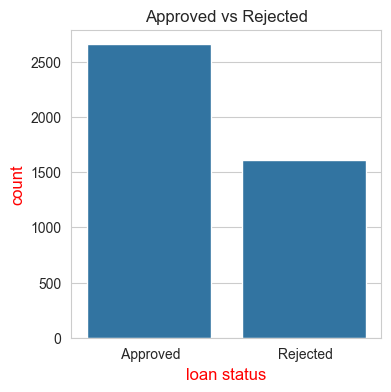

In [60]:
sns.set_style('whitegrid')
plt.figure(figsize=(4,4))
sns.countplot(x='loan_status',data=data)
plt.title('Approved vs Rejected')
plt.xlabel('loan status',fontsize=12 ,color='red')
plt.ylabel('count',fontsize=12,color='red')

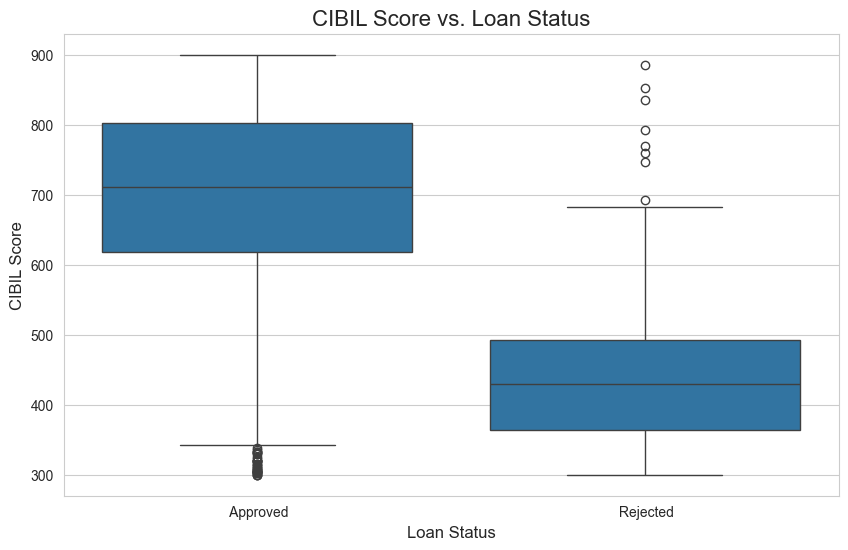

In [61]:
plt.figure(figsize=(10, 6))
sns.boxplot(x='loan_status', y='cibil_score', data=data)
plt.title('CIBIL Score vs. Loan Status', fontsize=16)
plt.xlabel('Loan Status', fontsize=12)
plt.ylabel('CIBIL Score', fontsize=12)
plt.show()

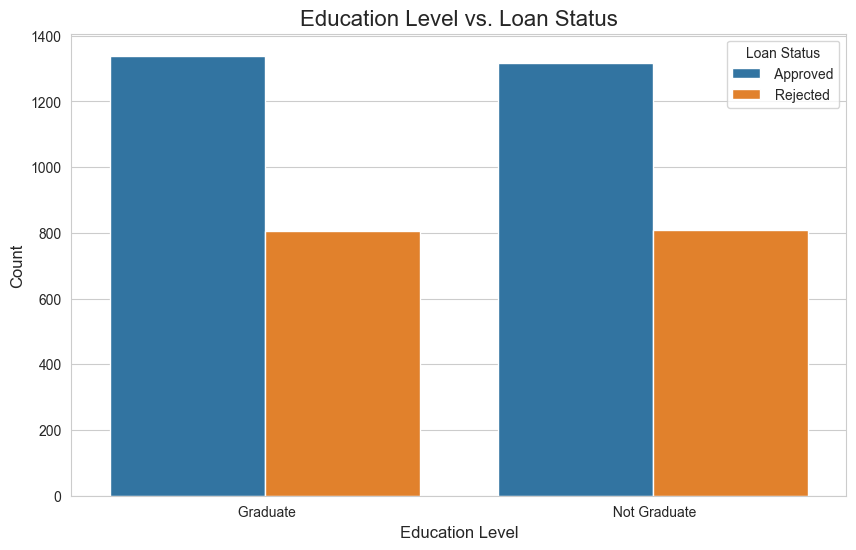

In [62]:

plt.figure(figsize=(10, 6))
sns.countplot(x='education', hue='loan_status', data=data)


plt.title('Education Level vs. Loan Status', fontsize=16)
plt.xlabel('Education Level', fontsize=12)
plt.ylabel('Count', fontsize=12)
plt.legend(title='Loan Status')
plt.show()

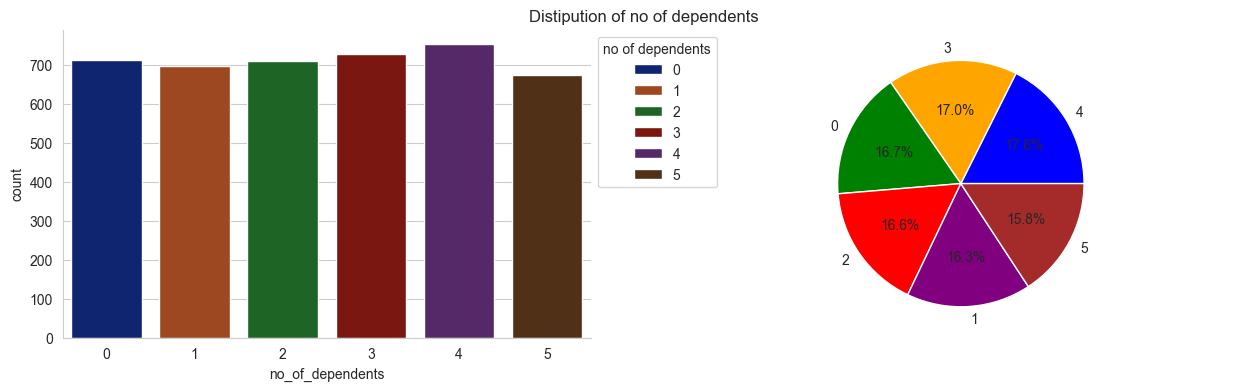

In [63]:

plt.figure (figsize=(15,4))
plt.title('Distipution of no of dependents')
plt.axis('off')
plt.subplot(1,2,1)
ax_1=sns.countplot(data, x = 'no_of_dependents',hue='no_of_dependents',palette='dark')
ax_1.spines['right'].set_visible(False);ax_1.spines['top'].set_visible(False)
plt.legend(title='no of dependents', bbox_to_anchor = ( 1, 1 ))

plt.subplot(1,2,2)
plt.pie( x = data['no_of_dependents'].value_counts().values,
        labels= data['no_of_dependents'].value_counts().index,
        autopct='%1.1f%%',colors =  ['blue','orange','green','red','purple','brown']

);

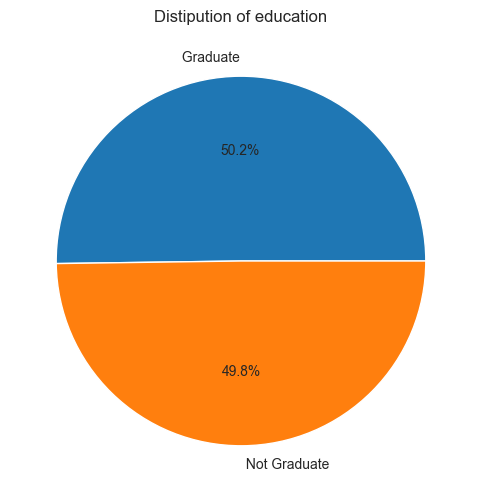

In [64]:
plt.figure (figsize=(18,6))
plt.title('Distipution of education')
plt.pie( x = data['education'].value_counts().values,
        labels= data['education'].value_counts().index,autopct='%1.1f%%');
plt.axis('off');
     

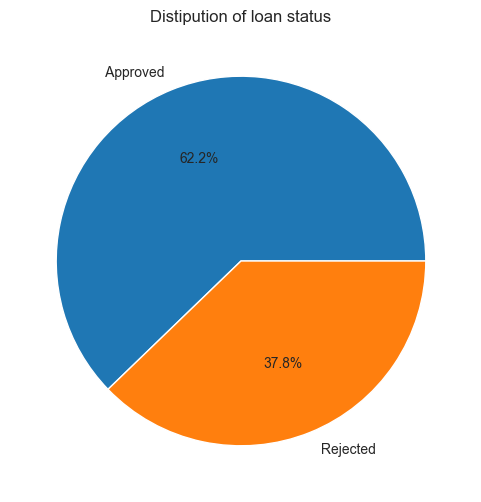

In [65]:
plt.figure (figsize=(18,6))
plt.title('Distipution of loan status')
plt.pie( x = data['loan_status'].value_counts().values,
        labels= data['loan_status'].value_counts().index,autopct='%1.1f%%');
plt.axis('off');
     

In [66]:
data[['loan_amount', 'income_annum']]

,loan_amount,income_annum
0,29900000,9600000
1,12200000,4100000
2,29700000,9100000
3,30700000,8200000
4,24200000,9800000
...,...,...
4264,2300000,1000000
4265,11300000,3300000
4266,23900000,6500000
4267,12800000,4100000


<Axes: xlabel='loan_amount', ylabel='Count'>

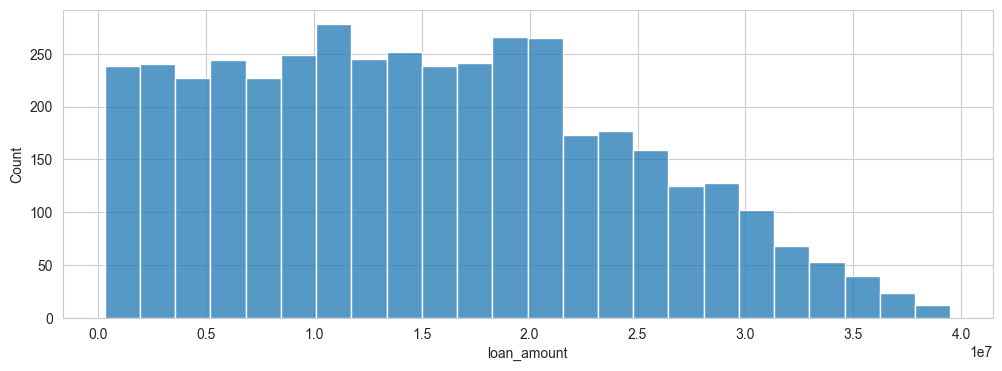

In [67]:
plt.figure(figsize=(12,4))
sns.histplot(data,x='loan_amount')

In [68]:

X = data.drop(columns=['loan_status', 'loan_id'])
y = data['loan_status']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)



In [69]:
X.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4269 entries, 0 to 4268
Data columns (total 11 columns):
 #   Column                    Non-Null Count  Dtype 
---  ------                    --------------  ----- 
 0   no_of_dependents          4269 non-null   int64 
 1   education                 4269 non-null   object
 2   self_employed             4269 non-null   object
 3   income_annum              4269 non-null   int64 
 4   loan_amount               4269 non-null   int64 
 5   loan_term                 4269 non-null   int64 
 6   cibil_score               4269 non-null   int64 
 7   residential_assets_value  4269 non-null   int64 
 8   commercial_assets_value   4269 non-null   int64 
 9   luxury_assets_value       4269 non-null   int64 
 10  bank_asset_value          4269 non-null   int64 
dtypes: int64(9), object(2)
memory usage: 367.0+ KB


In [70]:
le = LabelEncoder()
y = le.fit_transform(y)


In [71]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)


In [72]:
X_test.shape

(854, 11)

In [73]:
X_test.sample()

,no_of_dependents,education,self_employed,income_annum,loan_amount,loan_term,cibil_score,residential_assets_value,commercial_assets_value,luxury_assets_value,bank_asset_value
3084,4,Graduate,No,9700000,19400000,20,798,6400000,13700000,20300000,12800000


In [74]:
num_cols = X.select_dtypes(include=['int64','float64']).columns
cat_cols = X.select_dtypes(include=['object']).columns

preprocessor = ColumnTransformer([
    ('num', StandardScaler(), num_cols),
    ('cat', OneHotEncoder(handle_unknown='ignore'), cat_cols)
])

## Model Selection

### [ 1 ] Logistic Regression

In [75]:


lr_model = Pipeline([
    ('preprocess', preprocessor),
    ('clf', LogisticRegression(random_state=42))
])

lr_model.fit(X_train, y_train)

,steps,"[('preprocess', ...), ('clf', ...)]"
,transform_input,None
,memory,None
,verbose,False
,transformers,"[('num', ...), ('cat', ...)]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True


In [76]:
y_pred_lr = lr_model.predict(X_test)

print("Logistic Regression Training Accuracy:", accuracy_score(y_train, lr_model.predict( X_train )))
print("Logistic Regression Test Accuracy:", accuracy_score(y_test, y_pred_lr))
print(classification_report(y_test, y_pred_lr))

Logistic Regression Training Accuracy: 0.9144948755490483
Logistic Regression Test Accuracy: 0.9227166276346604
              precision    recall  f1-score   support

           0       0.93      0.95      0.94       531
           1       0.92      0.88      0.90       323

    accuracy                           0.92       854
   macro avg       0.92      0.91      0.92       854
weighted avg       0.92      0.92      0.92       854



In [77]:


mlflow.set_experiment("Loan_Approval_Classifier")
with mlflow.start_run(run_name="Logistic_Regression_Baseline"):
    print("--- Starting MLflow Run for Logistic Regression ---")
    model = LogisticRegression(random_state=42)
    full_pipeline = Pipeline(steps=[('preprocessor', preprocessor),
                                    ('classifier', model)])
    full_pipeline.fit(X_train, y_train)
    y_pred = full_pipeline.predict(X_test)
    print("\n--- Model Prediction Diagnosis ---")
    unique_predictions, counts = np.unique(y_pred, return_counts=True)
    print(f"Unique values predicted: {unique_predictions}")
    print(f"Counts of each value: {counts}\n")
    accuracy = accuracy_score(y_test, y_pred)
    report = classification_report(y_test, y_pred, output_dict=True)
    print(f"Model Accuracy: {accuracy:.4f}")
    print("\nClassification Report:")
    print(classification_report(y_test, y_pred, zero_division=0))
    print("\n--- Logging metrics to MLflow ---")
    mlflow.log_metric("accuracy", accuracy)
    if '0' in report:
        mlflow.log_metric("precision_class_0", report['0']['precision'])
        mlflow.log_metric("recall_class_0", report['0']['recall'])
        mlflow.log_metric("f1_score_class_0", report['0']['f1-score'])
    if '1' in report:
        mlflow.log_metric("precision_class_1", report['1']['precision'])
        mlflow.log_metric("recall_class_1", report['1']['recall'])
        mlflow.log_metric("f1_score_class_1", report['1']['f1-score'])
    mlflow.sklearn.log_model(full_pipeline, "logistic_regression_pipeline")
    
    print("\n--- Run finished. Check MLflow UI. ---");

--- Starting MLflow Run for Logistic Regression ---

--- Model Prediction Diagnosis ---
Unique values predicted: [0 1]
Counts of each value: [545 309]

Model Accuracy: 0.9227

Classification Report:
              precision    recall  f1-score   support

           0       0.93      0.95      0.94       531
           1       0.92      0.88      0.90       323

    accuracy                           0.92       854
   macro avg       0.92      0.91      0.92       854
weighted avg       0.92      0.92      0.92       854


--- Logging metrics to MLflow ---


2025/10/12 18:14:58 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instead.
2025/10/12 18:15:02 WARNING mlflow.models.model: Model logged without a signature and input example. Please set `input_example` parameter when logging the model to auto infer the model signature.



--- Run finished. Check MLflow UI. ---


<hr>

In [78]:
data.sample(5)[ ['no_of_dependents', 'education','loan_status' ] ]

,no_of_dependents,education,loan_status
2313,1,Graduate,Rejected
83,3,Graduate,Approved
3035,1,Not Graduate,Approved
1879,3,Not Graduate,Approved
894,1,Graduate,Approved


In [79]:
data[ ['no_of_dependents','loan_status' ] ].loc[[4030,3079]]

,no_of_dependents,loan_status
4030,1,Rejected
3079,4,Approved


##  2 desecion tree


In [80]:
dt_model = Pipeline([
    ('preprocess', preprocessor),
    ('clf', DecisionTreeClassifier (random_state=42))
])

dt_model.fit(X_train, y_train)

,steps,"[('preprocess', ...), ('clf', ...)]"
,transform_input,None
,memory,None
,verbose,False
,transformers,"[('num', ...), ('cat', ...)]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True


In [81]:
y_pred_dt = dt_model.predict(X_test)

print("decisionTree Training Accuracy:", accuracy_score(y_train, dt_model.predict( X_train )))
print("decisionTree Test Accuracy:", accuracy_score(y_test, y_pred_dt))
print(classification_report(y_test, y_pred_dt))

decisionTree Training Accuracy: 1.0
decisionTree Test Accuracy: 0.9730679156908665
              precision    recall  f1-score   support

           0       0.97      0.98      0.98       531
           1       0.97      0.96      0.96       323

    accuracy                           0.97       854
   macro avg       0.97      0.97      0.97       854
weighted avg       0.97      0.97      0.97       854



In [82]:
DT = dt_model.steps[1][1]

In [83]:
data.columns

Index(['loan_id', 'no_of_dependents', 'education', 'self_employed',
       'income_annum', 'loan_amount', 'loan_term', 'cibil_score',
       'residential_assets_value', 'commercial_assets_value',
       'luxury_assets_value', 'bank_asset_value', 'loan_status'],
      dtype='object')

In [84]:
X.columns

Index(['no_of_dependents', 'education', 'self_employed', 'income_annum',
       'loan_amount', 'loan_term', 'cibil_score', 'residential_assets_value',
       'commercial_assets_value', 'luxury_assets_value', 'bank_asset_value'],
      dtype='object')

In [85]:
X_train

,no_of_dependents,education,self_employed,income_annum,loan_amount,loan_term,cibil_score,residential_assets_value,commercial_assets_value,luxury_assets_value,bank_asset_value
1224,0,Graduate,Yes,9800000,23900000,14,459,1000000,13400000,21100000,7200000
478,3,Not Graduate,Yes,3600000,8600000,8,790,5400000,5900000,9800000,5200000
3065,2,Not Graduate,No,2000000,4000000,14,502,4900000,1500000,5400000,1300000
326,2,Not Graduate,Yes,3900000,11300000,12,516,3100000,0,10400000,4600000
2991,3,Not Graduate,No,2300000,8500000,12,557,3600000,1400000,6200000,1300000
...,...,...,...,...,...,...,...,...,...,...,...
23,0,Not Graduate,Yes,500000,1400000,2,551,900000,600000,1100000,300000
233,3,Not Graduate,Yes,8800000,34600000,8,386,14800000,16500000,18400000,6000000
3298,2,Not Graduate,Yes,6800000,15500000,12,338,9900000,1200000,21800000,8500000
1397,1,Not Graduate,Yes,9200000,24500000,4,545,25700000,0,20600000,13300000


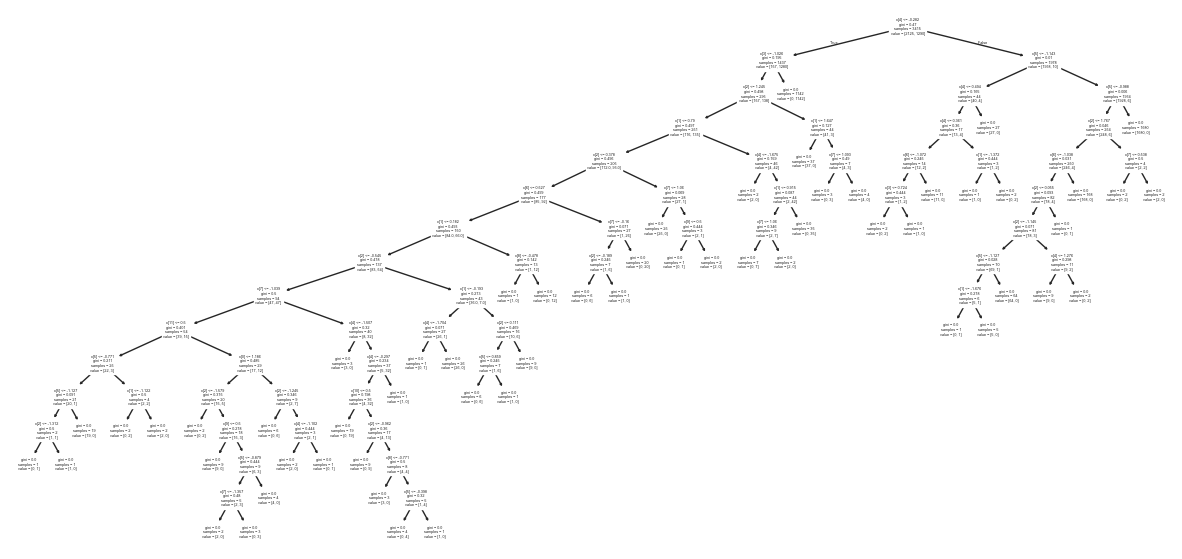

In [86]:
plt.figure( figsize=(15,7) )
plot_tree(DT, );

In [87]:


rf_model = Pipeline([
    ('preprocess', preprocessor),
    ('clf', RandomForestClassifier(n_estimators=200, random_state=42))
])

rf_model.fit(X_train, y_train)


,steps,"[('preprocess', ...), ('clf', ...)]"
,transform_input,None
,memory,None
,verbose,False
,transformers,"[('num', ...), ('cat', ...)]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True


In [88]:
y_pred_f = rf_model.predict(X_test)

print("Random Forest Test Accuracy:", accuracy_score(y_test, y_pred_f))
print(classification_report(y_test, y_pred_f))

Random Forest Test Accuracy: 0.9824355971896955
              precision    recall  f1-score   support

           0       0.98      0.99      0.99       531
           1       0.99      0.96      0.98       323

    accuracy                           0.98       854
   macro avg       0.98      0.98      0.98       854
weighted avg       0.98      0.98      0.98       854



In [89]:
import pickle
with open( 'rf_model.pkl', 'wb' ) as file :
    pickle.dump( rf_model, file  )

In [90]:
with mlflow.start_run(run_name="Random_Forest"):
    print("\n--- Starting MLflow Run for RandomForest ---")
 
    model = RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1)

  
    full_pipeline = Pipeline(steps=[('preprocessor', preprocessor),
                                    ('classifier', model)])

    full_pipeline.fit(X_train, y_train)

    y_pred = full_pipeline.predict(X_test)

  
    accuracy = accuracy_score(y_test, y_pred)
    report = classification_report(y_test, y_pred, output_dict=True)
    
    print(f"Model Accuracy: {accuracy:.4f}")
    print("\nClassification Report:")
    print(classification_report(y_test, y_pred))

    print("\n--- Logging metrics to MLflow ---")
    mlflow.log_metric("accuracy", accuracy)

    if '0' in report:
        mlflow.log_metric("precision_class_0", report['0']['precision'])
        mlflow.log_metric("recall_class_0", report['0']['recall'])
        mlflow.log_metric("f1_score_class_0", report['0']['f1-score'])
    if '1' in report:
        mlflow.log_metric("precision_class_1", report['1']['precision'])
        mlflow.log_metric("recall_class_1", report['1']['recall'])
        mlflow.log_metric("f1_score_class_1", report['1']['f1-score'])

    mlflow.sklearn.log_model(full_pipeline, "random_forest_pipeline")
    



--- Starting MLflow Run for RandomForest ---
Model Accuracy: 0.9813

Classification Report:
              precision    recall  f1-score   support

           0       0.98      0.99      0.99       531
           1       0.99      0.96      0.97       323

    accuracy                           0.98       854
   macro avg       0.98      0.98      0.98       854
weighted avg       0.98      0.98      0.98       854


--- Logging metrics to MLflow ---


2025/10/12 18:15:05 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instead.
2025/10/12 18:15:09 WARNING mlflow.models.model: Model logged without a signature and input example. Please set `input_example` parameter when logging the model to auto infer the model signature.


In [91]:
report_dict = classification_report(y_test, y_pred_f, output_dict=True)
report_dict

{'0': {'precision': 0.9777777777777777,
  'recall': 0.9943502824858758,
  'f1-score': 0.9859943977591037,
  'support': 531.0},
 '1': {'precision': 0.9904458598726115,
  'recall': 0.9628482972136223,
  'f1-score': 0.9764521193092621,
  'support': 323.0},
 'accuracy': 0.9824355971896955,
 'macro avg': {'precision': 0.9841118188251946,
  'recall': 0.9785992898497491,
  'f1-score': 0.9812232585341829,
  'support': 854.0},
 'weighted avg': {'precision': 0.9825691015677441,
  'recall': 0.9824355971896955,
  'f1-score': 0.9823853158629693,
  'support': 854.0}}

In [92]:
report_dict['macro avg']['recall']

0.9785992898497491

In [93]:
report_dict['accuracy']

0.9824355971896955

In [94]:
data.sample(4
            )

,loan_id,no_of_dependents,education,self_employed,income_annum,loan_amount,loan_term,cibil_score,residential_assets_value,commercial_assets_value,luxury_assets_value,bank_asset_value,loan_status
3106,3107,0,Graduate,No,5600000,11600000,12,466,15000000,7400000,21800000,7500000,Rejected
3363,3364,4,Not Graduate,No,3900000,10800000,20,433,4700000,1600000,14500000,2300000,Rejected
4259,4260,0,Not Graduate,Yes,4500000,11500000,14,509,13400000,2300000,15400000,5900000,Rejected
2707,2708,2,Not Graduate,Yes,7800000,29600000,14,568,-100000,8600000,27000000,7200000,Approved
